# Quantum Computing for Climate and Sustainability
**Knowledge Mapping + Experimental Evaluation (Classical vs QAOA) of a Renewable-Energy Scheduling Problem**

Runs top-to-bottom in Google Colab (Runtime > Run all). No quantum SDK install needed: QAOA is implemented with an exact NumPy state-vector simulator, so the experiment is fully reproducible and transparent.

Sections: 01 Intro · 02 Research Questions · 03-08 Literature dataset & analysis · 09 Knowledge graph · 10 Problem selection · 11-12 Problem data & formulation · 13 Classical baseline · 14-16 QUBO + QAOA + simulation · 17 Comparison · 18 Sustainability analysis · 19-22 Limitations, gaps, conclusions, future scope.

## 01-02. Introduction and Research Questions
**Central question:** Can a quantum computing technique be effectively applied to a small-scale climate/sustainability optimization problem, and what can we learn from comparing it with a classical solution?

| ID | Research question |
|---|---|
| RQ1 | What sustainability/climate problems are being investigated with quantum computing? |
| RQ2 | Which quantum techniques are most associated with these problems? |
| RQ3 | Which problem is suitable for a small-scale experimental implementation? |
| RQ4 | Can it be formulated for QAOA? |
| RQ5 | How does QAOA compare with a classical baseline (quality, objective, computation)? |
| RQ6 | What limitations prevent large-scale practical deployment? |

> We do **not** assume quantum wins. A classical win on a small instance is a valid result.

## 03. Literature Dataset
Only the 4 papers from the project plan are pre-filled. **Fields marked `TO_VERIFY` must be filled by reading the paper.** Add 6-11 more rows (target 10-15) by editing the CSV below; do not invent entries.

In [1]:
import io, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, networkx as nx, time, itertools
sns.set_theme(style="whitegrid")

csv_text = '''Paper_ID,Authors,Year,Title,Research_Area,Problem,Quantum_Technique,Application,Algorithm,Classical_Method,Implementation,Quantum_Advantage,Key_Finding,Limitation,Sustainability_Impact,Research_Gap
P1,Yadav & Rawat,2026,Knowledge Mapping of Quantum Computing for Climate Change Research and Sustainable Innovation,Climate,Research trends and gaps,Multiple,Climate research,Scientometric analysis,TO_VERIFY,Theory,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY
P2,Berger et al.,2021,Quantum Technologies for Climate Change: Preliminary Assessment,Climate;Energy,Assessment of quantum technology use for climate,Quantum Simulation;Optimization;Quantum Sensing,Energy Efficiency;Renewable Energy;Power Grids;Transportation;Environmental Monitoring,TO_VERIFY,TO_VERIFY,Theory,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY
P3,Root,2025,Quantum Technologies in the Context of Climate Change: Emphasizing Sustainability in a Responsible Innovation Approach,Sustainability,Footprint of quantum technology itself,Multiple,Sustainable Computing,Responsible innovation framework,TO_VERIFY,Theory,TO_VERIFY,TO_VERIFY,TO_VERIFY,Energy consumption and environmental footprint of quantum tech,TO_VERIFY
P4,Schwabe et al.,2025,Opportunities and Challenges of Quantum Computing for Climate Modeling,Climate,Climate modeling and prediction,QML;QAOA;VQE;QLBM;Hybrid Quantum-Classical,Climate Modeling;Climate Prediction,TO_VERIFY,HPC integration,Theory,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY
'''
df = pd.read_csv(io.StringIO(csv_text))
# To use your full CSV instead: df = pd.read_csv("literature.csv")
df.head()

,Paper_ID,Authors,Year,Title,Research_Area,Problem,Quantum_Technique,Application,Algorithm,Classical_Method,Implementation,Quantum_Advantage,Key_Finding,Limitation,Sustainability_Impact,Research_Gap
0,P1,Yadav & Rawat,2026,Knowledge Mapping of Quantum Computing for Cli...,Climate,Research trends and gaps,Multiple,Climate research,Scientometric analysis,TO_VERIFY,Theory,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY
1,P2,Berger et al.,2021,Quantum Technologies for Climate Change: Preli...,Climate;Energy,Assessment of quantum technology use for climate,Quantum Simulation;Optimization;Quantum Sensing,Energy Efficiency;Renewable Energy;Power Grids...,TO_VERIFY,TO_VERIFY,Theory,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY
2,P3,Root,2025,Quantum Technologies in the Context of Climate...,Sustainability,Footprint of quantum technology itself,Multiple,Sustainable Computing,Responsible innovation framework,TO_VERIFY,Theory,TO_VERIFY,TO_VERIFY,TO_VERIFY,Energy consumption and environmental footprint...,TO_VERIFY
3,P4,Schwabe et al.,2025,Opportunities and Challenges of Quantum Comput...,Climate,Climate modeling and prediction,QML;QAOA;VQE;QLBM;Hybrid Quantum-Classical,Climate Modeling;Climate Prediction,TO_VERIFY,HPC integration,Theory,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY,TO_VERIFY


## 04. Data Cleaning

In [2]:
df = df.replace("TO_VERIFY", np.nan)
df["Year"] = df["Year"].astype(int)
for col in ["Research_Area", "Quantum_Technique", "Application"]:
    df[col] = df[col].fillna("Unspecified").str.split(";").apply(lambda xs: [x.strip() for x in xs])
print("Rows:", len(df), "| Missing cells per column (to fill by reading papers):")
print(df.isna().sum()[lambda s: s > 0])

Rows: 4 | Missing cells per column (to fill by reading papers):
Algorithm                2
Classical_Method         3
Quantum_Advantage        4
Key_Finding              4
Limitation               4
Sustainability_Impact    3
Research_Gap             4
dtype: int64


## 05-08. Literature Analysis and Visualization
Counts below come from whatever rows are in the dataset; they update automatically as you add papers.

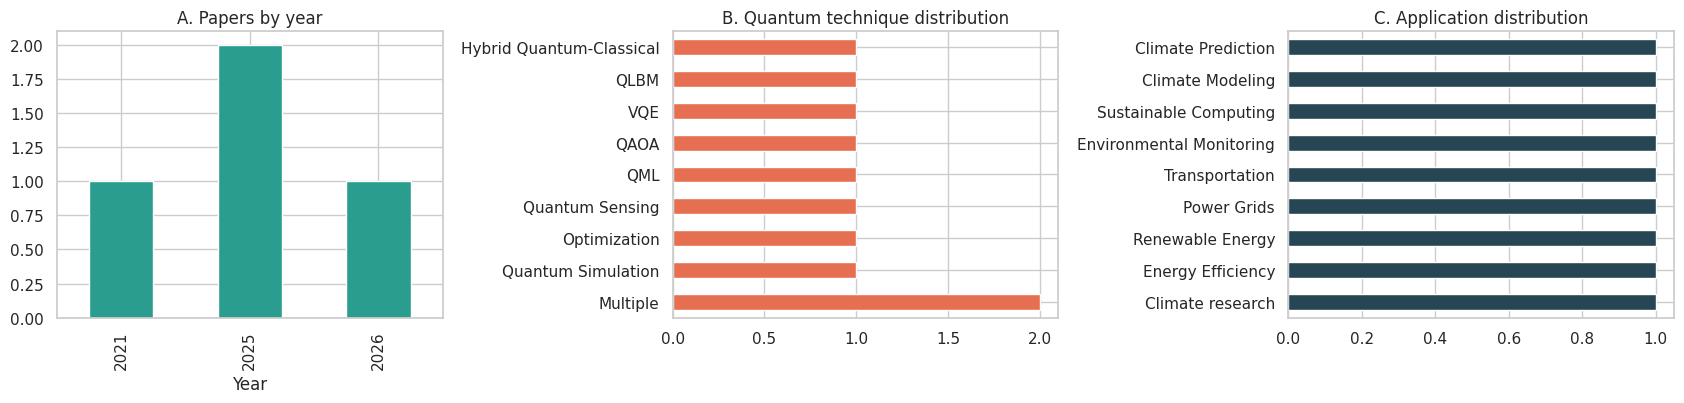

D. Evidence level:
Implementation
Theory    4
Name: count, dtype: int64


In [3]:
def count_multi(col):
    return pd.Series([x for xs in df[col] for x in xs]).value_counts()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
df["Year"].value_counts().sort_index().plot.bar(ax=ax[0], color="#2a9d8f"); ax[0].set_title("A. Papers by year")
count_multi("Quantum_Technique").plot.barh(ax=ax[1], color="#e76f51"); ax[1].set_title("B. Quantum technique distribution")
count_multi("Application").plot.barh(ax=ax[2], color="#264653"); ax[2].set_title("C. Application distribution")
plt.tight_layout(); plt.show()

# D. Evidence level (fill Implementation with: Theoretical/Simulation/Hybrid/Small-scale hardware/Demonstrated advantage)
print("D. Evidence level:"); print(df["Implementation"].value_counts())

## 09. Knowledge Graph (NetworkX)
Chains follow the plan: Technique -> Algorithm/Problem class -> Sustainability problem -> Application -> Expected impact. Extend edges as you read more papers.

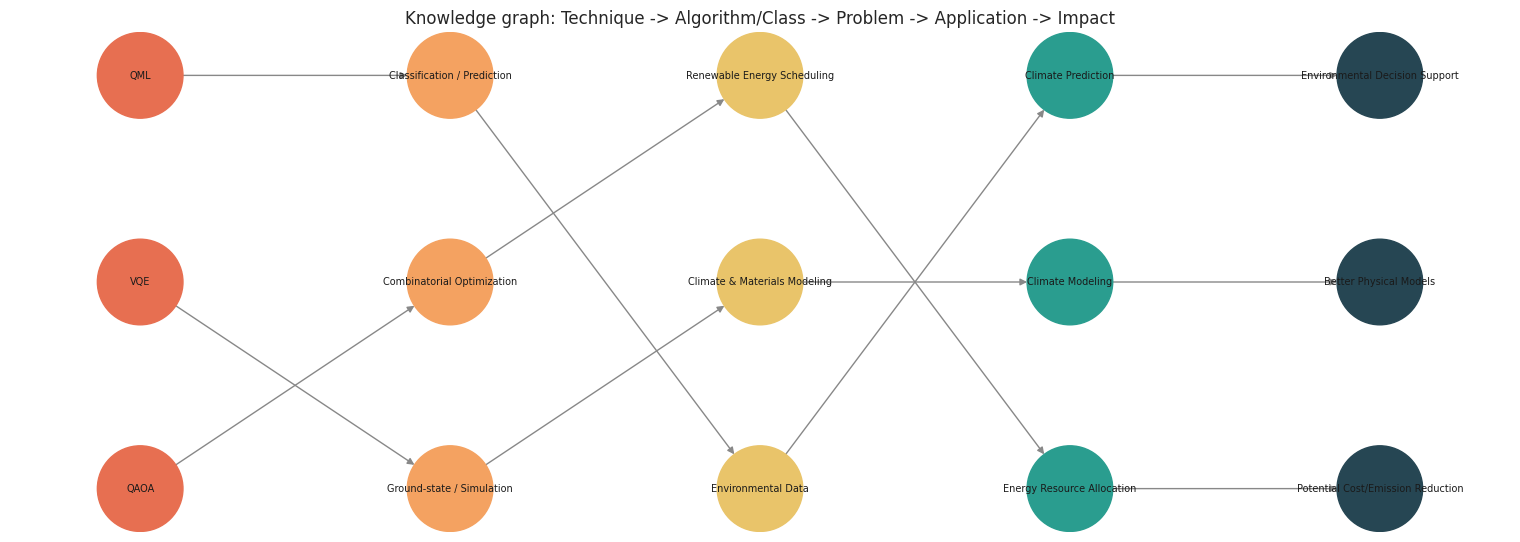

In [4]:
chains = [
  ["QAOA", "Combinatorial Optimization", "Renewable Energy Scheduling", "Energy Resource Allocation", "Potential Cost/Emission Reduction"],
  ["QML", "Classification / Prediction", "Environmental Data", "Climate Prediction", "Environmental Decision Support"],
  ["VQE", "Ground-state / Simulation", "Climate & Materials Modeling", "Climate Modeling", "Better Physical Models"],
]
layers = ["Technique", "Algorithm/Class", "Problem", "Application", "Impact"]
G = nx.DiGraph()
for ch in chains:
    for i, n in enumerate(ch):
        G.add_node(n, layer=i)
    G.add_edges_from(zip(ch[:-1], ch[1:]))
pos = nx.multipartite_layout(G, subset_key="layer")
plt.figure(figsize=(15, 5))
cols = ["#e76f51", "#f4a261", "#e9c46a", "#2a9d8f", "#264653"]
nx.draw(G, pos, with_labels=True, node_color=[cols[G.nodes[n]["layer"]] for n in G], node_size=3800,
        font_size=7, arrows=True, edge_color="#888")
plt.title("Knowledge graph: " + " -> ".join(layers)); plt.show()

## 10. Selection of Experimental Problem
| Option | Formulation | Small (<=16 qubits) | Classical solver | Literature support (P2) |
|---|---|---|---|---|
| A. Renewable-energy scheduling | Clear (binary dispatch) | Yes | MILP / brute force | Renewable energy, power grids |
| B. EV charging | Clear | Yes | MILP | verify |
| C. Grid optimization | Larger | Marginal | MILP | Power grids |
| D. Resource allocation | Clear | Yes | MILP | verify |
| E. Transportation | Routing grows fast | Marginal | MILP | Transportation |

**Selected: A. Renewable-energy scheduling** (recurring application area, clean QUBO form, exact classical baseline). Re-confirm after you complete the full paper set.

## 11. Problem Dataset
4 periods x 4 sources (Solar, Wind, Battery, Grid) = **16 binary variables = 16 qubits**. `x[t,s]=1` means source *s* is dispatched in period *t* at its available capacity. Values are **synthetic and illustrative** (state this in the paper).

In [5]:
periods = ["Morning", "Afternoon", "Evening", "Night"]
sources = ["Solar", "Wind", "Battery", "Grid"]
demand  = np.array([4, 5, 6, 3])                     # MWh required per period
cap = np.array([                                      # available capacity [t, s] (MWh)
    [2, 2, 2, 4],    # Morning
    [3, 2, 2, 4],    # Afternoon
    [0, 3, 3, 4],    # Evening  (no solar)
    [0, 2, 1, 4],    # Night
])
price = np.array([1.0, 1.5, 3.0, 6.0])               # cost per MWh
emis  = np.array([0.0, 0.0, 0.05, 0.70])             # tCO2 per MWh
BATTERY_PERIODS = 2                                    # battery stored energy = 2 dispatch units
lam = 4.0                                              # cost-equivalent weight of 1 tCO2 (scalarisation)
unit_cost = (price + lam * emis)                       # combined cost per MWh
pd.DataFrame(cap, index=periods, columns=sources).assign(Demand=demand)

,Solar,Wind,Battery,Grid,Demand
Morning,2,2,2,4,4
Afternoon,3,2,2,4,5
Evening,0,3,3,4,6
Night,0,2,1,4,3


## 12. Mathematical Formulation
Minimize  **sum_{t,s} (price_s + lambda*emis_s) * cap_{t,s} * x_{t,s}**  (+ tiny activation cost)

subject to  **sum_s cap_{t,s} x_{t,s} = D_t** for every period t (demand met exactly),
and  **sum_t x_{t,Battery} = 2** (battery energy budget), x binary.

Exact-supply is used so the constraint maps cleanly to a quadratic penalty (see 14).

In [6]:
n = 16
idx = lambda t, s: t * 4 + s
act = 0.01
c_lin = np.array([[unit_cost[s] * cap[t, s] + act for s in range(4)] for t in range(4)])

def evaluate(x):
    """x: 16-bit 0/1 vector -> dict with cost, emissions, feasibility."""
    X = np.asarray(x).reshape(4, 4)
    supply = (X * cap).sum(axis=1)
    feasible = bool(np.all(supply == demand) and X[:, 2].sum() == BATTERY_PERIODS)
    money = float((X * cap * price).sum())
    co2 = float((X * cap * emis).sum())
    obj = float((X * c_lin).sum())
    return dict(feasible=feasible, objective=obj, cost=money, co2=co2, supply=supply.tolist())

## 13. Classical Optimization (baseline)
Two classical methods: (a) exact brute-force over all 2^16 assignments, (b) integer linear programming with `scipy.optimize.milp`.

In [7]:
from scipy.optimize import milp, LinearConstraint, Bounds

# (a) Brute force (exact)
t0 = time.perf_counter()
ints = np.arange(2**n, dtype=np.int64)
bits = ((ints[:, None] >> np.arange(n)) & 1).astype(np.int8)          # bit i = variable i
Xall = bits.reshape(-1, 4, 4)
supply_all = (Xall * cap).sum(axis=2)
feas_mask = np.all(supply_all == demand, axis=1) & (Xall[:, :, 2].sum(axis=1) == BATTERY_PERIODS)
obj_all = (Xall * c_lin).reshape(-1, n).sum(axis=1)
obj_feas = np.where(feas_mask, obj_all, np.inf)
best_i = int(np.argmin(obj_feas))
t_bf = time.perf_counter() - t0
x_bf = bits[best_i]
print("Brute force optimum:", evaluate(x_bf), f"| feasible assignments: {feas_mask.sum()} of {2**n} | {t_bf:.3f}s")

# (b) MILP
t0 = time.perf_counter()
A, lo, hi = [], [], []
for t in range(4):
    row = np.zeros(n); row[[idx(t, s) for s in range(4)]] = cap[t]; A.append(row); lo.append(demand[t]); hi.append(demand[t])
row = np.zeros(n); row[[idx(t, 2) for t in range(4)]] = 1; A.append(row); lo.append(BATTERY_PERIODS); hi.append(BATTERY_PERIODS)
res = milp(c_lin.flatten(), constraints=LinearConstraint(np.array(A), lo, hi), integrality=np.ones(n), bounds=Bounds(0, 1))
t_milp = time.perf_counter() - t0
x_milp = np.round(res.x).astype(int)
print("MILP optimum:      ", evaluate(x_milp), f"| {t_milp:.4f}s")
E_opt = evaluate(x_bf)["objective"]

Brute force optimum: {'feasible': True, 'objective': 31.38, 'cost': 30.5, 'co2': 0.2, 'supply': [4, 5, 6, 3]} | feasible assignments: 8 of 65536 | 0.028s
MILP optimum:       {'feasible': True, 'objective': 31.38, 'cost': 30.5, 'co2': 0.2, 'supply': [4, 5, 6, 3]} | 0.0108s


## 14. Quantum Formulation: QUBO -> Hamiltonian
Equality constraints become penalties: **P * (sum_s cap_{t,s} x_{t,s} - D_t)^2** per period and **P * (sum_t x_{t,B} - 2)^2** for the battery.
Expanding gives a QUBO `E(x) = x^T Q x + const`. Substituting x = (1 - Z)/2 gives the Ising cost Hamiltonian used by QAOA; since it is diagonal, we store its 2^16 eigenvalues directly.

In [8]:
P = 3.0 * c_lin.max()          # penalty weight (must exceed the cost scale so infeasible states are worse)
Q = np.zeros((n, n)); const = 0.0
for i in range(n): Q[i, i] += c_lin.flat[i]
for t in range(4):
    vars_ = [idx(t, s) for s in range(4)]
    for a in vars_:
        Q[a, a] += P * (cap[t, a % 4] ** 2 - 2 * demand[t] * cap[t, a % 4])
        for b in vars_:
            if a < b: Q[a, b] += 2 * P * cap[t, a % 4] * cap[t, b % 4]
    const += P * demand[t] ** 2
bvars = [idx(t, 2) for t in range(4)]
for a in bvars:
    Q[a, a] += P * (1 - 2 * BATTERY_PERIODS)
    for b in bvars:
        if a < b: Q[a, b] += 2 * P
const += P * BATTERY_PERIODS ** 2

E = np.einsum("ki,ij,kj->k", bits, Q, bits) + const       # QUBO energy of every basis state
# sanity checks: QUBO minimum == classical optimum, and penalties vanish exactly on feasible states
E_feas_check = (E[feas_mask] - obj_all[feas_mask]); assert np.allclose(E_feas_check, 0), "QUBO mismatch"
assert abs(E.min() - E_opt) < 1e-9 and E.argmin() == best_i
print("QUBO verified: min energy =", round(E.min(), 4), "= classical optimum", round(E_opt, 4))

QUBO verified: min energy = 31.38 = classical optimum 31.38


## 15. QAOA Implementation (exact state-vector simulation)
Circuit for depth *p*: |+>^n, then repeat [ phase separator e^{-i gamma C} , mixer e^{-i beta sum X} ], then measure. Parameters (gamma, beta) are tuned by a classical optimizer (COBYLA) to minimise <C>.

In [9]:
from scipy.optimize import minimize
Emin, Emax = E.min(), E.max()
En = (E - Emin) / (Emax - Emin)                          # normalised cost in [0,1] for stable angles

def qaoa_state(params, p):
    gam, bet = params[:p], params[p:]
    psi = np.full(2**n, 1 / np.sqrt(2**n), dtype=complex)
    for l in range(p):
        psi *= np.exp(-1j * gam[l] * En * 2 * np.pi)      # phase separator (diagonal)
        c, s = np.cos(bet[l]), -1j * np.sin(bet[l])       # mixer exp(-i beta X) on each qubit
        T = psi.reshape((2,) * n)
        for q in range(n):
            T = np.moveaxis(T, q, 0)
            T = np.stack([c * T[0] + s * T[1], s * T[0] + c * T[1]])
            T = np.moveaxis(T, 0, q)
        psi = T.reshape(-1)
    return psi

def expectation(params, p):
    return float(np.real(np.sum(np.abs(qaoa_state(params, p)) ** 2 * En)))

def run_qaoa(p, restarts=4, seed=0, maxiter=150):
    rng = np.random.default_rng(seed); best = None; t0 = time.perf_counter(); evals = 0
    for r in range(restarts):
        x0 = np.concatenate([rng.uniform(0, 0.3, p), rng.uniform(0, np.pi / 2, p)])
        res = minimize(expectation, x0, args=(p,), method="COBYLA", options={"maxiter": maxiter}); evals += res.nfev
        if best is None or res.fun < best.fun: best = res
    return best, time.perf_counter() - t0, evals

results = {}
for p in [1, 2, 3]:
    best, dt, ev = run_qaoa(p)
    prob = np.abs(qaoa_state(best.x, p)) ** 2
    results[p] = dict(params=best.x, time=dt, evals=ev, prob=prob, exp_norm=best.fun)
    print(f"p={p}: <C>_norm={best.fun:.4f} | P(optimum)={prob[best_i]:.4f} | P(feasible)={prob[feas_mask].sum():.4f} | {dt:.1f}s, {ev} circuit evals")

p=1: <C>_norm=0.1605 | P(optimum)=0.0001 | P(feasible)=0.0004 | 6.7s, 519 circuit evals


p=2: <C>_norm=0.0994 | P(optimum)=0.0002 | P(feasible)=0.0017 | 14.6s, 600 circuit evals


p=3: <C>_norm=0.0997 | P(optimum)=0.0002 | P(feasible)=0.0016 | 18.7s, 600 circuit evals


## 16. Quantum Simulation: sampling like a real device
We sample 4096 shots from the final QAOA state and keep the best *feasible* bitstring measured (as one would on hardware).

Chosen depth p=2 | feasible shots: 0.1% | optimum sampled: 0.00%
Best feasible QAOA solution: {'feasible': True, 'objective': 31.39, 'cost': 30.5, 'co2': 0.2, 'supply': [4, 5, 6, 3]}


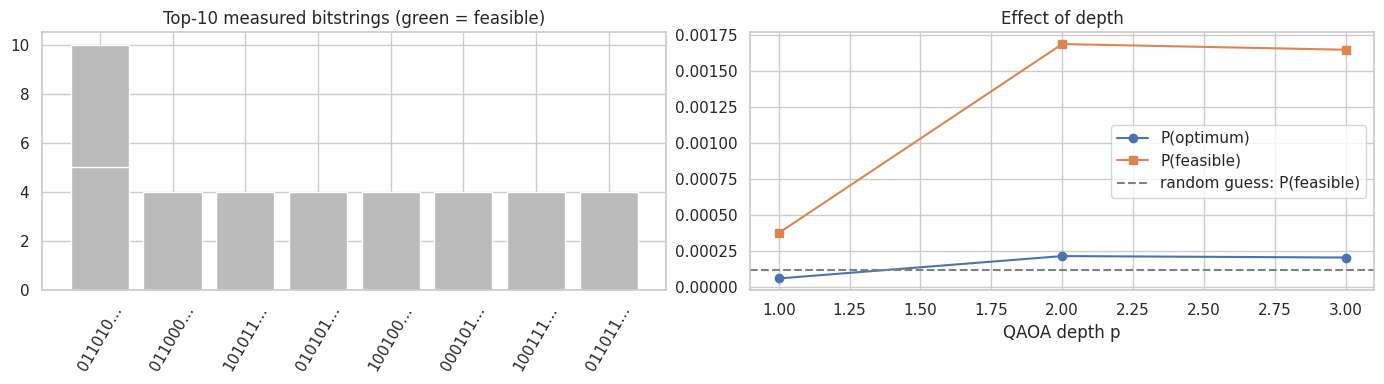

In [10]:
rng = np.random.default_rng(42); SHOTS = 4096
p_star = max(results, key=lambda p: results[p]["prob"][best_i])   # depth with best optimum probability
prob = results[p_star]["prob"]; prob = prob / prob.sum()
shots = rng.choice(2**n, size=SHOTS, p=prob)
counts = pd.Series(shots).value_counts()
shot_feas = feas_mask[shots]
best_shot = shots[shot_feas][np.argmin(obj_all[shots[shot_feas]])] if shot_feas.any() else None
print(f"Chosen depth p={p_star} | feasible shots: {shot_feas.mean():.1%} | optimum sampled: {(shots == best_i).mean():.2%}")
q_sol = evaluate(bits[best_shot]) if best_shot is not None else None
print("Best feasible QAOA solution:", q_sol)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
top = counts.head(10); ax[0].bar([format(i, "016b")[::-1][:6] + "…" for i in top.index], top.values, color=["#2a9d8f" if feas_mask[i] else "#bbb" for i in top.index])
ax[0].set_title("Top-10 measured bitstrings (green = feasible)"); ax[0].tick_params(axis="x", rotation=60)
ax[1].plot(list(results), [results[p]["prob"][best_i] for p in results], "o-", label="P(optimum)")
ax[1].plot(list(results), [results[p]["prob"][feas_mask].sum() for p in results], "s-", label="P(feasible)")
ax[1].axhline(feas_mask.sum() / 2**n, color="gray", ls="--", label="random guess: P(feasible)"); ax[1].set_xlabel("QAOA depth p"); ax[1].legend(); ax[1].set_title("Effect of depth")
plt.tight_layout(); plt.show()

## 17. Classical vs Quantum Comparison

In [11]:
rand_feas = feas_mask.sum() / 2**n
opt_prob = results[p_star]["prob"][best_i]
rows = [
  ["Brute force (classical)", 16, "CPU", evaluate(x_bf)["feasible"], evaluate(x_bf)["objective"], evaluate(x_bf)["cost"], evaluate(x_bf)["co2"], t_bf],
  ["MILP (classical)",        16, "CPU", evaluate(x_milp)["feasible"], evaluate(x_milp)["objective"], evaluate(x_milp)["cost"], evaluate(x_milp)["co2"], t_milp],
]
if q_sol: rows.append([f"QAOA p={p_star} (simulator)", 16, "NumPy state-vector sim", q_sol["feasible"], q_sol["objective"], q_sol["cost"], q_sol["co2"], results[p_star]["time"]])
cmp = pd.DataFrame(rows, columns=["Method", "Qubits/Vars", "Hardware", "Feasible", "Objective", "Cost", "CO2 (t)", "Time (s)"])
display(cmp.round(4))
gap = (q_sol["objective"] - E_opt) / E_opt * 100 if q_sol else float("nan")
print(f"QAOA optimality gap (best feasible shot): {gap:.2f}% | P(feasible) {results[p_star]['prob'][feas_mask].sum():.3f} vs random {rand_feas:.4f} | P(optimum) {opt_prob:.4f} vs random {1/2**n:.6f}")
print("Quantum advantage: NOT established. (Simulated QAOA costs far more time than MILP/brute force at this size.)")

,Method,Qubits/Vars,Hardware,Feasible,Objective,Cost,CO2 (t),Time (s)
0,Brute force (classical),16,CPU,True,31.38,30.5,0.2,0.0285
1,MILP (classical),16,CPU,True,31.38,30.5,0.2,0.0108
2,QAOA p=2 (simulator),16,NumPy state-vector sim,True,31.39,30.5,0.2,14.6212


QAOA optimality gap (best feasible shot): 0.03% | P(feasible) 0.002 vs random 0.0001 | P(optimum) 0.0002 vs random 0.000015
Quantum advantage: NOT established. (Simulated QAOA costs far more time than MILP/brute force at this size.)


## 18. Sustainability Analysis (both sides)

In [12]:
# Side 1: quantum FOR sustainability - compare the schedule against a fossil-only baseline (grid-only supply)
grid_only_co2 = demand.sum() * emis[3]; grid_only_cost = demand.sum() * price[3]
opt = evaluate(x_bf)
print(f"Optimal schedule: {opt['co2']:.2f} tCO2, cost {opt['cost']:.1f}  |  grid-only: {grid_only_co2:.2f} tCO2, cost {grid_only_cost:.1f}")
print(f"Emission reduction vs grid-only: {(1 - opt['co2'] / grid_only_co2) * 100:.1f}%  (note: achieved by the MODEL, classical solvers find it too)")

# Side 2: sustainability OF quantum computing - simulator energy (assumption-based, illustrative only)
CPU_WATTS = 15.0   # ASSUMPTION: typical shared-CPU power draw; change to your measured/assumed value
GRID_KG_PER_KWH = 0.7   # ASSUMPTION: approximate grid carbon intensity; cite your source
def footprint(seconds): kwh = CPU_WATTS * seconds / 3.6e6; return kwh, kwh * GRID_KG_PER_KWH * 1000
for name, sec in [("Brute force", t_bf), ("MILP", t_milp), (f"QAOA sim p={p_star}", results[p_star]["time"])]:
    kwh, g = footprint(sec); print(f"{name:18s} {sec:8.3f}s  ~{kwh:.6f} kWh  ~{g:.4f} g CO2")
print("Real quantum hardware footprint (cryogenics, control electronics) is NOT measured here - see Root (2025).")

Optimal schedule: 0.20 tCO2, cost 30.5  |  grid-only: 12.60 tCO2, cost 108.0
Emission reduction vs grid-only: 98.4%  (note: achieved by the MODEL, classical solvers find it too)
Brute force           0.028s  ~0.000000 kWh  ~0.0001 g CO2
MILP                  0.011s  ~0.000000 kWh  ~0.0000 g CO2
QAOA sim p=2         14.621s  ~0.000061 kWh  ~0.0426 g CO2
Real quantum hardware footprint (cryogenics, control electronics) is NOT measured here - see Root (2025).


## 19. Limitations
- Only 16 variables; instance is synthetic and simplified (fixed-capacity dispatch, no ramping, no battery dynamics).
- QAOA is **simulated noiselessly** (no hardware noise, no connectivity limits); exact simulation cost grows as 2^n.
- Penalty method: weight P affects landscape difficulty; constraint handling is a known QAOA weakness.
- Classical baselines solve this instance exactly in milliseconds; no scalability claim is made either way.
- Energy figures in section 18 rely on stated assumptions.

## 20. Research Gaps (from literature + this experiment)
Hardware gap · Data-encoding gap · Scalability gap (4-16 variables says nothing about thousands) · Benchmarking gap (strong classical baselines needed) · Quantum-advantage gap (potential != demonstrated) · Sustainability-of-quantum-computing gap.

## 21. Conclusions (fill with YOUR observed numbers after running)
1. The scheduling problem was formulated as a verified QUBO (16 qubits).
2. QAOA at depth p was applied; report P(feasible) and P(optimum) versus random guessing (section 15-16).
3. Compare best feasible QAOA objective against the classical optimum (section 17) and state whether quantum advantage was demonstrated (expected: not established).

## 22. Future Scope
Scale 16 -> 24 -> 32+ variables (use sparse/tensor-network simulators or hardware) · run on real cloud hardware with noise · real demand/solar/wind/EV/emissions data · multi-objective (cost + CO2 + losses) · measure the quantum computation's own footprint · climate simulation / QML for prediction.